# Практическая работа № 1
## Анализ цифрового образовательного следа средствами Google Colab и BigQuery

**Курс:** «Методы анализа больших данных»

| Поле | Заполните |
|---|---|
| ФИО | Теркун Степан Анатольевич |
| Группа | ИНФА-231 |
| Номер варианта | 11 |
| Дата | 13.10.2026 |

### Сквозной кейс

Мы анализируем обезличенный цифровой образовательный след и учимся выполнять **одинаковую аналитическую логику в двух средах**:

**CSV → Google Colab / pandas → BigQuery / GoogleSQL → визуализация → педагогическая интерпретация.**

### Что важно

1. Мы работаем с **одним учебным файлом** `practice01_oulad.csv`.
2. Одна строка — это не «один клик», а сочетание **обучающийся × день × ресурс**.
3. `sum_click` — число взаимодействий с ресурсом в этот день.
4. Низкая активность — только **статистический сигнал**, а не характеристика способностей обучающегося.
5. Не меняйте код без необходимости: сначала выполните готовые ячейки сверху вниз.

## Теоретический минимум

### Big Data и 5V

- **Volume** — объём данных;
- **Velocity** — скорость появления событий;
- **Variety** — разные типы данных и сущностей;
- **Veracity** — качество и достоверность;
- **Value** — педагогическая ценность результата.

### DataFrame

`DataFrame` — таблица в памяти Python.  
В этой работе переменная `df` будет содержать весь учебный CSV.

### Агрегирование

Подробные строки можно объединить в показатели уровня обучающегося:

```text
много строк ресурсов → одна строка на обучающегося
```

В `pandas` используется `groupby`, а в SQL — `GROUP BY`.

| pandas | SQL |
|---|---|
| фильтр `df[...]` | `WHERE` |
| `groupby()` | `GROUP BY` |
| `sum()` | `SUM()` |
| `nunique()` | `COUNT(DISTINCT ...)` |
| `sort_values()` | `ORDER BY` |

## Шаг 1. Подключение библиотек

Выполните ячейку без изменений.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("Готово. Версия pandas:", pd.__version__)

Готово. Версия pandas: 2.2.3


## Шаг 2. Загрузка `practice01_oulad.csv`

Нажмите ▶. Colab предложит выбрать файл с компьютера.

Выберите **`practice01_oulad.csv`**, выданный преподавателем.

> Если среда Colab перезапустилась, загруженный ранее файл исчезнет. Это нормально — загрузите CSV снова.

In [2]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("Файл не выбран.")

DATA_PATH = next(iter(uploaded))
print("Загружен файл:", DATA_PATH)

Saving practice01_oulad (4).csv to practice01_oulad (4).csv
Загружен файл: practice01_oulad (4).csv


In [3]:
df = pd.read_csv(DATA_PATH)

print("Размерность (строки, столбцы):", df.shape)
print("Уникальных обучающихся:", df["id_student"].nunique())
print("Диапазон day:", df["day"].min(), "—", df["day"].max())

df.head()

Размерность (строки, столбцы): (161160, 8)
Уникальных обучающихся: 1819
Диапазон day: 0 — 59


,code_module,code_presentation,id_student,day,id_site,sum_click,activity_type,final_result
0,BBB,2013J,532477,0,703721,38,homepage,Pass
1,BBB,2013J,532477,0,703722,13,forumng,Pass
2,BBB,2013J,532477,0,703732,17,forumng,Pass
3,BBB,2013J,532477,0,703722,1,forumng,Pass
4,BBB,2013J,532477,0,703722,15,forumng,Pass


### Контрольные значения

Если используется эталонный файл преподавателя, должно получиться:

```text
строк:           161160
столбцов:        8
обучающихся:     1819
day:             0–59
```

Если значения другие, **не продолжайте**: проверьте выбранный CSV.

Ожидаемые столбцы:

```text
code_module
code_presentation
id_student
day
id_site
sum_click
activity_type
final_result
```

## Шаг 3. Первичная проверка данных (EDA)

**EDA (Exploratory Data Analysis)** — первичная разведка данных.

Сейчас мы ответим на вопросы:

1. Какие столбцы и типы данных есть?
2. Есть ли пропуски?
3. Есть ли полные дубликаты строк?
4. Как распределён `sum_click`?
5. Нет ли отрицательных дней?

In [4]:
print("ТИПЫ ДАННЫХ")
print(df.dtypes)

print("\nПРОПУСКИ")
print(df.isna().sum())

print("\nПОЛНЫЕ ДУБЛИКАТЫ")
print(df.duplicated().sum())

print("\nDAY")
print(df["day"].describe())

print("\nSUM_CLICK")
print(df["sum_click"].describe(percentiles=[0.5, 0.9, 0.99]))

ТИПЫ ДАННЫХ
code_module          object
code_presentation    object
id_student            int64
day                   int64
id_site               int64
sum_click             int64
activity_type        object
final_result         object
dtype: object

ПРОПУСКИ
code_module          0
code_presentation    0
id_student           0
day                  0
id_site              0
sum_click            0
activity_type        0
final_result         0
dtype: int64

ПОЛНЫЕ ДУБЛИКАТЫ
14820

DAY
count    161160.000000
mean         27.727060
std          17.688303
min           0.000000
25%          12.000000
50%          27.000000
75%          44.000000
max          59.000000
Name: day, dtype: float64

SUM_CLICK
count    161160.000000
mean          3.268423
std           4.535917
min           1.000000
50%           2.000000
90%           7.000000
99%          22.000000
max         125.000000
Name: sum_click, dtype: float64


### Ваш вывод по качеству данных

> **Ваш вывод:**  
> Пропусков нет, отрицательных `day` нет (дни от 0 до 59). Обычно `sum_click` маленький, но максимум намного больше типичного значения. Большое значение не обязательно ошибка: студент мог много раз открывать ресурс, например перед тестом.

## Шаг 4. Переход от подробных строк к уровню обучающегося

Берём первые **30 дней**:

```text
day = 0 ... 29
```

Для каждого обучающегося рассчитаем:

- `total_clicks` — суммарное число взаимодействий;
- `active_days` — число дней, когда были записи;
- `resources_used` — число разных ресурсов;
- `final_result` — итог обучения.

Это пример операции **агрегирования**.

In [5]:
early = df[df["day"].between(0, 29)].copy()

student_metrics = (
    early.groupby("id_student")
    .agg(
        total_clicks=("sum_click", "sum"),
        active_days=("day", "nunique"),
        resources_used=("id_site", "nunique"),
        final_result=("final_result", "first"),
    )
    .reset_index()
)

print("Обучающихся с активностью в первые 30 дней:", len(student_metrics))
student_metrics.head()

Обучающихся с активностью в первые 30 дней: 1767


,id_student,total_clicks,active_days,resources_used,final_result
0,23798,146,11,15,Distinction
1,27759,123,12,21,Fail
2,30091,153,7,19,Pass
3,31014,309,21,10,Withdrawn
4,31849,414,17,23,Pass


### Контроль

Для эталонного файла должно получиться:

```text
1767 обучающихся
```

Почему не 1819?  
Потому что **52 обучающихся не имеют записей в днях 0–29**, хотя присутствуют в 60-дневном срезе.

## Шаг 5. Сквозной пример: прозрачный сигнал низкой ранней активности

Это **не машинное обучение** и не диагноз. Мы используем простую эвристику, чтобы понять принцип Learning Analytics.

Найдём нижний квартиль — 25-й перцентиль:

- по `total_clicks`;
- по `active_days`.

Сигнал ставится только при выполнении **обоих** условий.

In [6]:
q25_clicks = student_metrics["total_clicks"].quantile(0.25)
q25_days = student_metrics["active_days"].quantile(0.25)

student_metrics["support_signal"] = (
    (student_metrics["total_clicks"] <= q25_clicks)
    & (student_metrics["active_days"] <= q25_days)
)

student_metrics["is_success"] = student_metrics["final_result"].isin(
    ["Pass", "Distinction"]
)

comparison = (
    student_metrics.groupby("support_signal")["is_success"]
    .agg(students_count="count", success_rate="mean")
    .reset_index()
)

print("Q25 по кликам:", q25_clicks)
print("Q25 по активным дням:", q25_days)
comparison

Q25 по кликам: 34.0
Q25 по активным дням: 4.0


,support_signal,students_count,success_rate
0,False,1380,0.652899
1,True,387,0.364341


### Контрольные результаты эталонного файла

Ожидается:

```text
Q25 total_clicks = 34
Q25 active_days  = 4
```

| support_signal | обучающихся | Pass/Distinction |
|---|---:|---:|
| `False` | 1380 | ≈ 65,3% |
| `True` | 387 | ≈ 36,4% |

### Как это интерпретировать

Корректно:

> В данном потоке низкая ранняя активность статистически связана с более низкой долей успешного завершения.

Некорректно:

> Низкая активность вызывает неуспех.

По этим данным **нельзя доказать причинность**.

## Шаг 6. Базовая визуализация

Выполните готовую ячейку.

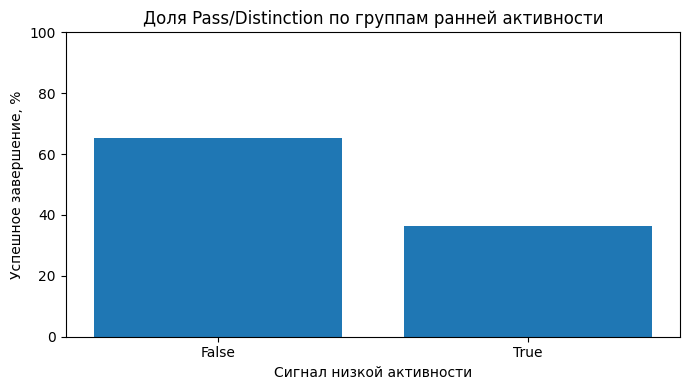

In [7]:
plot_data = comparison.copy()
plot_data["success_percent"] = plot_data["success_rate"] * 100

plt.figure(figsize=(7, 4))
plt.bar(
    plot_data["support_signal"].astype(str),
    plot_data["success_percent"]
)
plt.title("Доля Pass/Distinction по группам ранней активности")
plt.xlabel("Сигнал низкой активности")
plt.ylabel("Успешное завершение, %")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Шаг 7. Индивидуальный вариант

> **Мой вариант № 11**  
> **Вопрос:** в какой день у каждого студента была последняя активность в первые 60 дней (`MAX(day)`)? Что нельзя сказать о студенте только по последней записи?

In [8]:
last = (
    df.groupby("id_student")
    .agg(last_day=("day", "max"), final_result=("final_result", "first"))
    .reset_index()
)

print("Студентов:", len(last))
print(last["last_day"].describe())

last.groupby("final_result")["last_day"].median()

Студентов: 1819
count    1819.000000
mean       50.120946
std        13.548702
min         0.000000
25%        49.000000
50%        55.000000
75%        58.000000
max        59.000000
Name: last_day, dtype: float64


,last_day
final_result,
Distinction,58.0
Fail,53.0
Pass,57.0
Withdrawn,45.0


### График по вашему варианту

Используйте `matplotlib`. Не требуется сложное оформление.

> Заголовок графика должен объяснять, что показано.

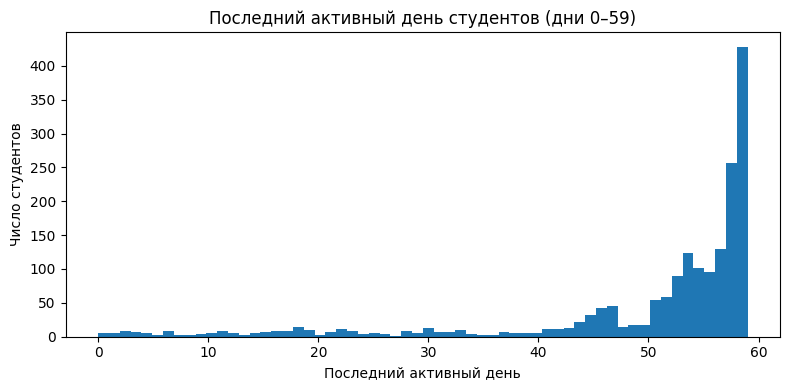

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(last["last_day"], bins=60)
plt.title("Последний активный день студентов (дни 0–59)")
plt.xlabel("Последний активный день")
plt.ylabel("Число студентов")
plt.tight_layout()
plt.show()

# Шаг 8. BigQuery Sandbox

Подробно действия описаны в `README.md`.

## 8.1. Создайте dataset

В текущем интерфейсе:

```text
Explorer
→ ваш проект
→ Datasets
→ Create dataset
```

Если кнопки нет:

```text
⋮ рядом с проектом → Create dataset
```

Параметры:

```text
Dataset ID:     learning_analytics
Location type:  Multi-region
Location:       EU
```

> Если Google Cloud Project уже существует, **новый проект создавать не нужно**.

## 8.2. Загрузите CSV

```text
learning_analytics
→ Create table
→ Create table from: Upload
→ practice01_oulad.csv
```

Destination:

```text
Dataset: learning_analytics
Table:   oulad_events
```

Schema:

```text
Auto detect = включить
```

Advanced options:

```text
Header rows to skip = 1
```

Если там стоит `0`: щёлкните по `0` → удалите → введите `1` → нажмите `Tab`.

Проверьте Schema:

```text
id_student → INTEGER
day        → INTEGER
id_site    → INTEGER
sum_click  → INTEGER
```

## Шаг 9. Контрольный SQL-запрос

В BigQuery нажмите **SQL query**.

Замените `edu-analytics-sandbox-511513` на идентификатор своего проекта.

```sql
SELECT
  COUNT(*) AS rows_count,
  COUNT(DISTINCT id_student) AS students,
  MIN(day) AS min_day,
  MAX(day) AS max_day
FROM `edu-analytics-sandbox-511513.learning_analytics.oulad_events`;
```

Результат: `161160`, `1819`, `0`, `59` — совпало.

Ожидается:

```text
rows_count = 161160
students   = 1819
min_day    = 0
max_day    = 59
```

Если результат другой — сначала проверьте загрузку таблицы.

## Шаг 10. Базовый SQL-аналог `groupby`

```sql
SELECT
  id_student,
  SUM(sum_click) AS total_clicks,
  COUNT(DISTINCT day) AS active_days,
  COUNT(DISTINCT id_site) AS resources_used
FROM `edu-analytics-sandbox-511513.learning_analytics.oulad_events`
WHERE day BETWEEN 0 AND 29
GROUP BY id_student
ORDER BY total_clicks DESC;
```

Для эталонного файла запрос должен вернуть **1767 строк**. Результат: **1767 строк** — совпало.

### Почему `BETWEEN 0 AND 29`?

`BETWEEN` включает обе границы:

```text
0 ... 29 = 30 значений дня
```

`BETWEEN 0 AND 30` дал бы уже 31 значение.

## Шаг 11. SQL по вашему варианту

```sql
SELECT
  id_student,
  MAX(day) AS last_day,
  ANY_VALUE(final_result) AS final_result
FROM `edu-analytics-sandbox-511513.learning_analytics.oulad_events`
WHERE day BETWEEN 0 AND 59
GROUP BY id_student
ORDER BY last_day;
```

Тот же расчёт через оконную функцию:

```sql
SELECT DISTINCT
  id_student,
  MAX(day) OVER (PARTITION BY id_student) AS last_day
FROM `edu-analytics-sandbox-511513.learning_analytics.oulad_events`
WHERE day BETWEEN 0 AND 59
ORDER BY last_day;
```

**Что получилось:**  
Оба запроса вернули по 1819 строк — по одной на студента, как в Colab. Первые строки результата:

| id_student | last_day | final_result |
|---:|---:|---|
| 547979 | 0 | Withdrawn |
| 516447 | 0 | Withdrawn |
| 510868 | 0 | Withdrawn |
| 577239 | 0 | Withdrawn |
| 2296908 | 0 | Withdrawn |

**Совпадает ли логика с расчётом в Colab?**  
Да. `groupby("id_student")` = `GROUP BY id_student`, `max` = `MAX(day)`.

## Шаг 12. Педагогическая интерпретация

> **Ваш итоговый вывод:**  
> Показатель - последний день, когда у студента есть запись в системе. У половины из 1819 студентов последняя активность на 55й день или позже, а у четверти — на 49й день или раньше. Медиана последнего дня у сдавших выше: Distinction - 58, Pass -57, Fail - 53, Withdrawn - 45. Это только связь, а не причина. По этим данным нельзя доказать, что ранний уход из системы вызывает неуспех. Могут быть и другие причины:
студент скачал материалы и учится без системы, заболел, был занят на работе,

*   студент скачал материалы и учится без системы
*   временно нет интернета
*   студент заболел и мн. др.

Получен сигнал для педагогической проверки и предложения адресной поддержки, например, преподаватель может написать студентам, которые давно не заходили, и спросить, нужна ли им помощь.

---
## Чек-лист перед сдачей

- [ ] Заполнены ФИО, группа и номер варианта.
- [ ] Загружен `practice01_oulad.csv`.
- [ ] Получено 161 160 строк и 1 819 обучающихся.
- [ ] Выполнен EDA.
- [ ] Получены 1 767 обучающихся в окне 0–29 дней.
- [ ] Выполнен индивидуальный вариант в Colab.
- [ ] Построен один график.
- [ ] В BigQuery задано `Header rows to skip = 1`.
- [ ] Числовые поля имеют тип `INTEGER`.
- [ ] Контрольный SQL дал 161 160 строк и 1 819 обучающихся.
- [ ] Вставлен SQL своего варианта.
- [ ] Педагогический вывод не содержит причинных утверждений и ярлыков.

### Что сдавать

Сохраните блокнот:

```text
Фамилия_Группа_ПР01.ipynb
```

**File / Файл → Download / Скачать → Download .ipynb**.